# TorsionFlow pipeline: few-step conformer generation on GEOM-QM9

This is the project's actual training pipeline. It trains a **twist-angle flow model** on real GEOM-QM9 conformers, generates conformers for the official test molecules in **1, 2, 5 and 20 steps**, and scores them with the benchmark's own scoring script.

**The question it answers** (README, step 4):

> Can a twist-angle model reach Torsional Diffusion's 20-step quality (AMR-R ≈ 0.178 Å) in fewer steps?

**What it reuses, and what is ours:**

| Piece | Source |
|---|---|
| Data loading, conformer-matched data, molecule features | Torsional Diffusion (patched for Windows) |
| The network (E(3)-equivariant, sees 3D neighbourhoods) | Torsional Diffusion, unchanged except: it gets the time *t* instead of a noise level, and its output isn't rescaled |
| Twisting bonds, building start shapes, turning results into RDKit molecules | Torsional Diffusion |
| Scoring (COV, AMR) | Torsional Diffusion's `evaluate_confs.py`, the benchmark script |
| **Training: flow matching on twist angles** (curved path, target velocity, losses) | **ours**: the same recipe as `training_walkthrough.ipynb` parts F–H |
| **Few-step sampler** (S Euler steps) | **ours**: walkthrough part I |

The walkthrough notebook explains every idea with a toy model; this notebook runs them for real.

**Two modes**, set in the first code cell:
- `MODE = "smoke"`: a small subset and a small network. Runs on a CPU in about 5 minutes. It checks that every piece runs, and that the network *can* learn (the memorisation check). It does **not** train long enough to learn the real task: on this task the network needs tens of thousands of steps before the loss moves (Torsional Diffusion's own training behaves the same). **Its scores are not results.**
- `MODE = "full"`: all of GEOM-QM9, the paper's network size, 250 epochs. **Needs the GPU.**

**Before running:**
1. Step 1 environment (`step1_setup/SETUP.md`).
2. `data/qm9.tar.gz` unpacked into `data/QM9/`, plus the name list:
   `python step2_reproduce/make_names.py data/qm9.tar.gz QM9/qm9 data/QM9/qm9_names.txt`
3. Torsional Diffusion copied to `torsional-diffusion/` and patched:
   `python step2_reproduce/patch_windows.py torsional-diffusion`

## 0. Settings

The full settings are Torsional Diffusion's published ones for QM9 (same network size, learning rate and schedule), so the two models are comparable.

In [1]:
from pathlib import Path

MODE = "smoke"           # "smoke": CPU, small subset, checks the plumbing. "full": GPU, all of GEOM-QM9.

ROOT = Path.cwd().parent                     # the TorsionFlow folder (this notebook lives in notebooks/)
TD   = ROOT / "torsional-diffusion"          # patched Torsional Diffusion code
DATA = ROOT / "data" / "QM9"                 # unpacked qm9.tar.gz
RUN  = ROOT / "runs" / f"qm9_flow_{MODE}"    # checkpoints, generated conformers, results

SETTINGS = {
    #            molecules (0 = all)                                       network size
    "smoke": dict(train_mols=1000, val_mols=200, test_mols=20, epochs=5,   ns=16, nv=4, layers=2),
    "full":  dict(train_mols=0,    val_mols=0,   test_mols=1000, epochs=250, ns=32, nv=8, layers=4),
}
CFG = SETTINGS[MODE] | dict(
    batch_size=32, lr=1e-3, scheduler_patience=20,   # Torsional Diffusion's defaults
    max_radius=5.0,                                  # Å: atoms closer than this exchange messages
    loss="velocity_mse",                             # or "endpoint_cos" (section 3)
    steps_list=[1, 2, 5, 20],                        # sampling steps to compare
    seed=0, embed_seed=42,                           # embed_seed must not be 0 (RDKit gives identical shapes)
    eval_workers=8,
)
RUN.mkdir(parents=True, exist_ok=True)
print(f"MODE = {MODE}\n" + "\n".join(f"  {k:18s} {v}" for k, v in CFG.items()))

MODE = smoke
  train_mols         1000
  val_mols           200
  test_mols          20
  epochs             5
  ns                 16
  nv                 4
  layers             2
  batch_size         32
  lr                 0.001
  scheduler_patience 20
  max_radius         5.0
  loss               velocity_mse
  steps_list         [1, 2, 5, 20]
  seed               0
  embed_seed         42
  eval_workers       8


In [2]:
import copy, json, math, os, pickle, random, re, subprocess, sys, time
from argparse import Namespace

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem
from torch_geometric.loader import DataLoader
from torch_geometric.transforms import BaseTransform

RDLogger.DisableLog("rdApp.*")

# --- checks: is everything in place? ---
assert (TD / "diffusion" / "score_model.py").exists(), f"Torsional Diffusion not found at {TD}"
assert "qm9_names.txt" in (TD / "utils" / "dataset.py").read_text(encoding="utf-8") or \
       "_names.txt" in (TD / "utils" / "dataset.py").read_text(encoding="utf-8"), \
       "torsional-diffusion is not patched (patch 7 missing): run step2_reproduce/patch_windows.py"
assert (DATA / "standardized_pickles").is_dir(), f"unpack data/qm9.tar.gz into {DATA.parent}"
assert (DATA / "qm9_names.txt").exists(), "make the name list: step2_reproduce/make_names.py"

# --- import Torsional Diffusion. The first import builds a lookup table (about 1-2 minutes,
#     once) and saves it as two files in the current folder, so import from inside its folder. ---
sys.path.insert(0, str(TD))
_here = os.getcwd(); os.chdir(TD)
from utils.dataset import ConformerDataset
from utils.featurization import qm9_types
from utils.torsion import modify_conformer
from utils.utils import get_model
from diffusion.sampling import get_seed, embed_seeds, perturb_seeds, pyg_to_mol, InferenceDataset
os.chdir(_here)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(min(8, os.cpu_count() or 1))
random.seed(CFG["seed"]); np.random.seed(CFG["seed"]); torch.manual_seed(CFG["seed"])
print("device:", device, "| torch", torch.__version__)

C:\Users\showk\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cpu | torch 2.7.1+cpu


## 1. Data

**What's loaded.** For each molecule: its graph, atom features (44 per atom for QM9), its rotatable bonds, and up to 30 real conformers that were already *conformer-matched* (rewritten as RDKit local structure + real twist angles; walkthrough part C). These are the shapes the model learns to produce.

**The train/val/test split stores positions, not names**, in the alphabetical list of molecule files. On Windows, 121 pairs of molecules whose names differ only in upper/lower case overwrite each other, the list shifts, and **784 of the 1000 test molecules would land in training**. Patch 7 rebuilds the list from `qm9_names.txt` (taken from the archive), which puts 0 test molecules in training.

**The training example** is built exactly like walkthrough part F, with Torsional Diffusion's own twisting function:
1. pick one real conformer x₁ (at random, as Torsional Diffusion does);
2. draw a random offset δ for every rotatable bond, uniform on (−π, π): the random start is x₁ twisted by δ;
3. draw a time t, uniform on (0, 1);
4. x_t = x₁ twisted by (1 − t)·δ;
5. target velocity = −δ.

**Feeding t to the network.** Torsional Diffusion's network takes a noise level σ and embeds log σ. We pass σ = σ_min·(σ_max/σ_min)^t, which makes that embedding a straight-line function of t. Nothing inside the network changes.

In [3]:
SIGMA_MIN, SIGMA_MAX = 0.01 * np.pi, np.pi

def time_as_sigma(t):
    "The network embeds log(sigma); this sigma makes the embedding a linear function of t."
    return SIGMA_MIN * (SIGMA_MAX / SIGMA_MIN) ** t

class TorsionFlowTransform(BaseTransform):
    "Turns one molecule into one training example: a point x_t on the curved path, and its velocity."
    def __call__(self, data):          # PyG >= 2.x calls forward(); this keeps old versions working too
        return self.forward(data)

    def forward(self, data):
        data.pos = random.choice(data.pos)                                      # 1. a real conformer x1
        k = int(data.edge_mask.sum())
        delta = np.random.uniform(-np.pi, np.pi, size=k)                        # 2. random start offset
        t = np.random.uniform()                                                 # 3. time
        data.pos = modify_conformer(data.pos, data.edge_index.T[data.edge_mask],
                                    data.mask_rotate, (1 - t) * delta)          # 4. x_t
        data.node_sigma = time_as_sigma(t) * torch.ones(data.num_nodes)
        data.t = torch.tensor([t], dtype=torch.float32)
        data.target = torch.tensor(-delta, dtype=torch.float32)                 # 5. target velocity
        return data

def make_dataset(mode, limit):
    return ConformerDataset(str(DATA / "qm9") + "/", str(DATA / "split.npy"), mode, qm9_types, "qm9",
                            transform=TorsionFlowTransform(), num_workers=1, limit_molecules=limit or None,
                            cache=str(DATA / f"cache_flow_{limit or 'all'}"),
                            pickle_dir=str(DATA / "standardized_pickles"))

t0 = time.time()
train_set = make_dataset("train", CFG["train_mols"])
val_set = make_dataset("val", CFG["val_mols"])
print(f"\ntrain {len(train_set)} molecules, val {len(val_set)} molecules  ({time.time() - t0:.0f} s; "
      f"cached for next time)")
print("(The first full-mode run featurises ~120k molecules once, which takes a while on one CPU core.)")

Reusing preprocessing from cache D:\ML_project_TACFM\TorsionFlow\data\QM9\cache_flow_1000.train


Reusing preprocessing from cache D:\ML_project_TACFM\TorsionFlow\data\QM9\cache_flow_200.val



train 924 molecules, val 188 molecules  (1 s; cached for next time)
(The first full-mode run featurises ~120k molecules once, which takes a while on one CPU core.)


**Check the path before training on it.** Twist x₁ to x_t, then apply the target velocity for the remaining time (1 − t). That must land exactly back on x₁, using Torsional Diffusion's own twisting function. If it doesn't, the training target is wrong.

⚠️ Torsional Diffusion's `modify_conformer` **changes the coordinates you pass in, in place**, as well as returning the result. Training and generation are safe (they always work on copies), but any code that twists stored data must `.clone()` first. Without that, this check would compare against an already-twisted "original" and corrupt the stored molecule.

In [4]:
# a molecule with several twists (not e.g. acetylene, where twisting moves nothing)
raw = max(train_set.datapoints[:200], key=lambda d: int(d.edge_mask.sum()))
x1 = raw.pos[0].clone()                                         # clone: modify_conformer works in place
bonds, mask = raw.edge_index.T[raw.edge_mask], raw.mask_rotate
delta = np.random.uniform(-np.pi, np.pi, size=int(raw.edge_mask.sum()))
t = 0.3
xt = modify_conformer(x1.clone(), bonds, mask, (1 - t) * delta)
back = modify_conformer(xt.clone(), bonds, mask, (1 - t) * (-delta))   # follow velocity -delta for time 1-t
print(f"{raw.canonical_smi}: {int(raw.edge_mask.sum())} rotatable bonds, {len(raw.pos)} real conformers")
print(f"x_t is {float((xt - x1).norm(dim=1).max()):.2f} Å away from x1 at its furthest atom")
print(f"x_t + (1-t) * velocity lands back on x1 to within {float((back - x1).norm(dim=1).max()):.1e} Å")

loader = DataLoader(train_set, batch_size=CFG["batch_size"], shuffle=True)
batch = next(iter(loader))
print(f"\none batch: {batch.num_graphs} molecules, {batch.num_nodes} atoms, "
      f"{int(batch.edge_mask.sum())} rotatable bonds -> target velocities {tuple(batch.target.shape)}")

C#CC#CC#CC#CC: 8 rotatable bonds, 1 real conformers
x_t is 1.71 Å away from x1 at its furthest atom
x_t + (1-t) * velocity lands back on x1 to within 8.4e-08 Å

one batch: 32 molecules, 512 atoms, 179 rotatable bonds -> target velocities (179,)


**What loss is possible?** Before training, compute the lowest loss *any* model could reach on this data, with no model at all. For a given in-between shape, check which of the molecule's real conformers it could be heading to (every bond's offset must fit inside the path); the best possible prediction is the average of their velocities, and their spread is what's left over. This gives the targets to compare training against: "predict 0" is the starting point, the floor is the best case.

In [5]:
def wrap(x):
    return np.remainder(x + np.pi, 2 * np.pi) - np.pi

def torsion_angles(d):
    "Twist angle of every rotatable bond, for every real conformer: [conformers, bonds]."
    nbrs = {}
    for a, b in d.edge_index.T.tolist():
        nbrs.setdefault(a, []).append(b)
    quads = np.array([(next(x for x in nbrs[u] if x != v), u, v, next(x for x in nbrs[v] if x != u))
                      for u, v in d.edge_index.T[d.edge_mask].tolist()])
    pos = np.stack([p.numpy() for p in d.pos])
    a, u, v, b = (pos[:, quads[:, i]] for i in range(4))
    b0, b1, b2 = a - u, v - u, b - v
    b1 = b1 / np.linalg.norm(b1, axis=-1, keepdims=True)
    p_ = b0 - (b0 * b1).sum(-1, keepdims=True) * b1
    q_ = b2 - (b2 * b1).sum(-1, keepdims=True) * b1
    return np.arctan2((np.cross(b1, p_) * q_).sum(-1), (p_ * q_).sum(-1))

def loss_floor(datapoints, samples=40, seed=0):
    rng = np.random.default_rng(seed)
    se, base, n = np.zeros(5), np.zeros(5), np.zeros(5)
    for d in datapoints:
        phi = torsion_angles(d); C, K = phi.shape
        for _ in range(samples):
            i, t = rng.integers(C), rng.uniform(); delta = rng.uniform(-np.pi, np.pi, K)
            diff = wrap(phi[i] + (1 - t) * delta - phi)                      # offsets to every real conformer
            ok = (np.abs(diff) < (1 - t) * np.pi).all(1)                     # conformers it could be heading to
            k = min(int(t * 5), 4)
            se[k] += (diff[ok] / (1 - t)).var(0).sum(); base[k] += (delta ** 2).sum(); n[k] += K
    return se.sum() / n.sum(), base.sum() / n.sum(), se / n

FLOOR, PREDICT0, FLOOR_BY_T = loss_floor(train_set.datapoints[:2000])
print(f"velocity MSE   predict 0: {PREDICT0:.2f}   best possible: {FLOOR:.2f}")
print("best possible by time t:  " + "  ".join(f"t~{0.1 + 0.2 * k:.1f}: {v:.2f}" for k, v in enumerate(FLOOR_BY_T)))

velocity MSE   predict 0: 3.29   best possible: 0.48
best possible by time t:  t~0.1: 1.40  t~0.3: 0.75  t~0.5: 0.22  t~0.7: 0.03  t~0.9: 0.00


## 2. The network

Torsional Diffusion's network: atoms within 5 Å exchange messages built from 3D directions (E(3)-equivariant), and a final layer outputs **one number per rotatable bond**. That's exactly what we need: a twist velocity per bond. It already handles rotating the whole molecule (output unchanged) and mirror images (output flips sign).

Two settings differ from Torsional Diffusion: the time goes in through σ (section 1), and `scale_by_sigma=False`, because their output was rescaled to match diffusion scores, and ours is a velocity.

In [6]:
model_args = Namespace(
    in_node_features=44, in_edge_features=4, ns=CFG["ns"], nv=CFG["nv"], sigma_embed_dim=32,
    sigma_min=SIGMA_MIN, sigma_max=SIGMA_MAX, num_conv_layers=CFG["layers"], max_radius=CFG["max_radius"],
    radius_embed_dim=50, scale_by_sigma=False, use_second_order_repr=False,
    no_residual=False, no_batch_norm=False)
model = get_model(model_args).to(device)
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")

with torch.no_grad():
    out = model(copy.deepcopy(batch).to(device)).edge_pred
print(f"one batch in -> {tuple(out.shape)} velocities out (one per rotatable bond; "
      f"matches the {tuple(batch.target.shape)} targets)")

parameters: 54,796


one batch in -> (179,) velocities out (one per rotatable bond; matches the (179,) targets)


## 3. Loss functions

The same two angle losses as walkthrough part G. (The 3D-distance loss needs a differentiable version of the twisting function over whole batches; it's the next thing to add, for step 5.)

- **velocity_mse**: (predicted velocity − true velocity)², the standard flow-matching loss.
- **endpoint_cos**: turn the velocity into a predicted destination and score the angle error with 1 − cos, which handles wrap-around. Weights early times more, where 1-step generation lives.

In [7]:
def bond_time(batch):
    "The time t of the molecule each rotatable bond belongs to."
    return batch.t[batch.batch[batch.edge_index[0][batch.edge_mask]]]

def loss_velocity_mse(pred, batch):
    return F.mse_loss(pred, batch.target)

def loss_endpoint_cos(pred, batch):
    err = (1 - bond_time(batch)) * (pred - batch.target)
    return (1 - torch.cos(err)).mean()

LOSSES = {"velocity_mse": loss_velocity_mse, "endpoint_cos": loss_endpoint_cos}

b = copy.deepcopy(batch).to(device)
print("perfect prediction:", {k: round(f(b.target, b).item(), 6) for k, f in LOSSES.items()})
print("predicting 0:      ", {k: round(f(torch.zeros_like(b.target), b).item(), 3) for k, f in LOSSES.items()})

perfect prediction: {'velocity_mse': 0.0, 'endpoint_cos': 0.0}
predicting 0:       {'velocity_mse': 3.258, 'endpoint_cos': 0.403}


**Can the network learn at all? (memorisation check)** Take 16 molecules, fix one training example for each (fixed t and offset), and train a *fresh* copy of the network on just those. Any working network should drive the loss to about 0 within a few hundred steps (on this machine: 3.7 -> about 0.2 by step 300). If it can't, something is broken (a patch, a library version, the data reaching the network), and there's no point training on the full data. About a minute on a CPU.

In [8]:
from torch_geometric.data import Batch

def fixed_example(d0, rng):
    d = copy.deepcopy(d0)
    d.pos = d.pos[0].clone()
    k = int(d.edge_mask.sum()); delta = rng.uniform(-np.pi, np.pi, size=k); t = rng.uniform(0.3, 0.9)
    d.pos = modify_conformer(d.pos, d.edge_index.T[d.edge_mask], d.mask_rotate, (1 - t) * delta)
    d.node_sigma = time_as_sigma(t) * torch.ones(d.num_nodes)
    d.target = torch.tensor(-delta, dtype=torch.float32)
    return d

rng = np.random.default_rng(0)
mem = Batch.from_data_list([fixed_example(d, rng) for d in train_set.datapoints[:400]
                            if int(d.edge_mask.sum()) >= 2][:16]).to(device)
probe = get_model(model_args).to(device)
probe_opt = torch.optim.Adam(probe.parameters(), lr=1e-3)
for step in range(1, 501):
    loss = F.mse_loss(probe(copy.deepcopy(mem)).edge_pred, mem.target)
    probe_opt.zero_grad(); loss.backward(); probe_opt.step()
    if step in (1, 100, 200, 300, 400, 500):
        print(f"step {step:3d}  loss {loss.item():.3f}")
print("network can learn: PASS" if loss.item() < 0.3 else "network can learn: FAIL - stop and investigate")
del probe, probe_opt

step   1  loss 3.707


step 100  loss 0.538


step 200  loss 0.408


step 300  loss 0.219


step 400  loss 0.208


step 500  loss 0.019
network can learn: PASS


## 4. Training

Plain Adam with Torsional Diffusion's schedule (learning rate × 0.7 when the validation loss stops improving for `scheduler_patience` epochs). The best model on validation is saved to `runs/.../best_model.pt`.

Each epoch also prints the validation error **split by time t**, next to the best possible value. Late times are nearly determined (best possible ≈ 0), so that's where learning shows up first. **On the GPU, the first sign that training works is those late-time numbers falling well below "predict 0".**

Watch the **seconds per epoch** too: that number decides how many experiments later steps can afford.

In [9]:
opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.7,
                                                   patience=CFG["scheduler_patience"], min_lr=CFG["lr"] / 100)
train_loader = DataLoader(train_set, batch_size=CFG["batch_size"], shuffle=True)
val_loader = DataLoader(val_set, batch_size=CFG["batch_size"], shuffle=False)
loss_fn = LOSSES[CFG["loss"]]

def run_epoch(loader, train):
    model.train(train)
    total, count = 0.0, 0
    se_t, n_t = np.zeros(5), np.zeros(5)                        # velocity error by time (validation)
    for batch in loader:
        batch = batch.to(device)
        with torch.set_grad_enabled(train):
            pred = model(batch).edge_pred
            loss = loss_fn(pred, batch)
        if train:
            opt.zero_grad(); loss.backward(); opt.step()
        else:
            k = (bond_time(batch) * 5).long().clamp(max=4).cpu().numpy()
            err = ((pred - batch.target) ** 2).detach().cpu().numpy()
            for j in range(5):
                se_t[j] += err[k == j].sum(); n_t[j] += (k == j).sum()
        total += loss.item() * batch.num_graphs; count += batch.num_graphs
    return (total / count, se_t / np.maximum(n_t, 1)) if not train else total / count

history, best = [], float("inf")
for epoch in range(1, CFG["epochs"] + 1):
    t0 = time.time()
    tr = run_epoch(train_loader, True)
    va, va_t = run_epoch(val_loader, False)
    sched.step(va)
    history.append(dict(epoch=epoch, train=tr, val=va, lr=opt.param_groups[0]["lr"], secs=time.time() - t0,
                        val_by_t=va_t.tolist()))
    if va < best:
        best = va
        torch.save(model.state_dict(), RUN / "best_model.pt")
    print(f"epoch {epoch:3d}  train {tr:.4f}  val {va:.4f}  lr {opt.param_groups[0]['lr']:.1e}  "
          f"{time.time() - t0:.0f} s" + ("  (best, saved)" if va == best else ""))
    print("           val by t:  " + "  ".join(f"{v:.2f} (best {f:.2f})" for v, f in zip(va_t, FLOOR_BY_T)))

json.dump(dict(cfg=CFG, model_args=vars(model_args), history=history), open(RUN / "training.json", "w"), indent=1)

epoch   1  train 3.3117  val 3.3839  lr 1.0e-03  3 s  (best, saved)
           val by t:  3.27 (best 1.40)  3.21 (best 0.75)  3.47 (best 0.22)  3.44 (best 0.03)  3.46 (best 0.00)


epoch   2  train 3.3356  val 3.4232  lr 1.0e-03  3 s
           val by t:  3.49 (best 1.40)  3.85 (best 0.75)  3.28 (best 0.22)  2.77 (best 0.03)  3.39 (best 0.00)


epoch   3  train 3.4265  val 3.1346  lr 1.0e-03  3 s  (best, saved)
           val by t:  3.13 (best 1.40)  3.04 (best 0.75)  3.13 (best 0.22)  2.89 (best 0.03)  3.39 (best 0.00)


epoch   4  train 3.2974  val 3.2750  lr 1.0e-03  4 s
           val by t:  3.11 (best 1.40)  3.18 (best 0.75)  3.13 (best 0.22)  3.31 (best 0.03)  3.73 (best 0.00)


epoch   5  train 3.2691  val 3.4010  lr 1.0e-03  4 s
           val by t:  3.35 (best 1.40)  3.36 (best 0.75)  3.59 (best 0.22)  3.41 (best 0.03)  3.01 (best 0.00)


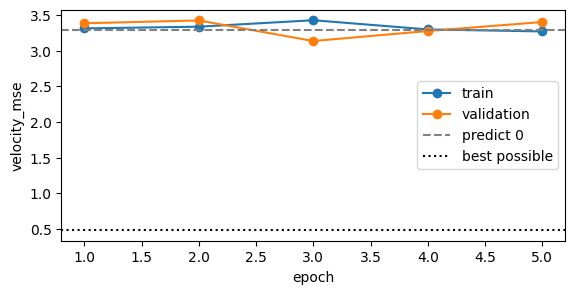

average 3 s per epoch on cpu


In [10]:
h = pd.DataFrame(history)
plt.figure(figsize=(6.5, 3))
plt.plot(h.epoch, h.train, "o-", label="train"); plt.plot(h.epoch, h.val, "o-", label="validation")
if CFG["loss"] == "velocity_mse":
    plt.axhline(PREDICT0, ls="--", c="gray", label="predict 0")
    plt.axhline(FLOOR, ls=":", c="k", label="best possible")
plt.xlabel("epoch"); plt.ylabel(CFG["loss"]); plt.legend(); plt.show()
print(f"average {h.secs.mean():.0f} s per epoch on {device}")

## 5. Generating conformers in S steps

For each test molecule with K real conformers, make 2K (the benchmark rule):
1. RDKit builds 2K local structures, and every twist is set at random: the **random start** (t = 0). This is Torsional Diffusion's own start-shape code.
2. Repeat S times: ask the model for velocities at the current shapes and time, then twist by velocity × 1/S.

S = 0 means no model at all (random twists), the baseline. For a fair comparison, **every S starts from exactly the same shapes** (all random seeds are reset first).

In [11]:
model.load_state_dict(torch.load(RUN / "best_model.pt", map_location=device))
model.eval()
test = pd.read_csv(DATA / "test_smiles.csv").head(CFG["test_mols"])

def embed(mol, n):
    AllChem.EmbedMultipleConfs(mol, numConfs=n, randomSeed=CFG["embed_seed"])
    return mol

@torch.no_grad()
def generate(smi, n_confs, steps):
    mol, data = get_seed(smi, dataset="qm9")
    if not mol:
        return None
    confs, _ = embed_seeds(mol, data, n_confs, embed_func=embed)
    if not confs:
        return None
    if int(data.edge_mask.sum()) > 0:
        confs = perturb_seeds(confs)                                  # random twists = the start
        ds = InferenceDataset(confs)
        for i in range(steps):
            for batch in DataLoader(ds, batch_size=CFG["batch_size"], shuffle=False):
                b = copy.deepcopy(batch).to(device)
                b.node_sigma = time_as_sigma(i / steps) * torch.ones(b.num_nodes, device=device)
                velocity = model(b).edge_pred.cpu().numpy()
                ds.apply_torsion_and_update_pos(batch, velocity / steps)
    return [pyg_to_mol(mol, c, rmsd=False) for c in confs]

def generate_all(steps):
    random.seed(CFG["seed"]); np.random.seed(CFG["seed"]); torch.manual_seed(CFG["seed"])
    out, t0 = {}, time.time()
    for raw_smi, k, smi in test.itertuples(index=False):
        mols = generate(smi, 2 * k, steps)
        if mols:
            out[smi] = mols
    path = RUN / f"test_{steps}steps.pkl"
    pickle.dump(out, open(path, "wb"))
    print(f"S = {steps:2d}: {len(out)}/{len(test)} molecules, "
          f"{sum(len(v) for v in out.values())} conformers, {time.time() - t0:.0f} s -> {path.name}")
    return path

gen_paths = {s: generate_all(s) for s in [0] + CFG["steps_list"]}

S =  0: 20/20 molecules, 650 conformers, 2 s -> test_0steps.pkl


S =  1: 20/20 molecules, 650 conformers, 3 s -> test_1steps.pkl


S =  2: 20/20 molecules, 650 conformers, 4 s -> test_2steps.pkl


S =  5: 20/20 molecules, 650 conformers, 7 s -> test_5steps.pkl


S = 20: 20/20 molecules, 650 conformers, 25 s -> test_20steps.pkl


## 6. Scoring, with the benchmark's own script

`evaluate_confs.py` compares every generated conformer with every real one (symmetry-aware RMSD on heavy atoms) and reports coverage and AMR at a range of thresholds. QM9 uses **0.5 Å**, so we read that block.

Reference rows are from the Torsional Diffusion paper (Table 7). In smoke mode they're there only to show the format: a tiny network trained for a few minutes can't come close.

In [12]:
def evaluate(path):
    cmd = [sys.executable, "evaluate_confs.py", "--confs", str(path),
           "--test_csv", str(DATA / "test_smiles.csv"), "--true_mols", str(DATA / "test_mols.pkl"),
           "--dataset", "qm9", "--n_workers", str(CFG["eval_workers"]), "--limit_mols", str(CFG["test_mols"])]
    env = dict(os.environ, PYTHONIOENCODING="utf-8")
    out = subprocess.run(cmd, cwd=TD, capture_output=True, text=True, encoding="utf-8",
                         errors="replace", env=env).stdout
    block = out.split("threshold 0.5\n")[1]
    num = lambda label: [float(x) for x in re.search(label + r": Mean = ([\d.]+), Median = ([\d.]+)", block).groups()]
    (cr, _), (ar, _) = num("Recall Coverage"), num("Recall AMR")
    (cp, _), (ap, _) = num("Precision Coverage"), num("Precision AMR")
    return dict(COV_R=cr, AMR_R=ar, COV_P=cp, AMR_P=ap)

results = {}
for s, path in gen_paths.items():
    t0 = time.time()
    results[s] = evaluate(path)
    print(f"scored S = {s:2d} in {time.time() - t0:.0f} s")

table = pd.DataFrame({("random twists (no model)" if s == 0 else f"ours, {s} step" + ("s" if s > 1 else "")): r
                      for s, r in results.items()}).T
table.loc["paper: RDKit"] = dict(COV_R=85.1, AMR_R=0.235, COV_P=86.8, AMR_P=0.232)
table.loc["paper: Torsional Diffusion, 20 steps"] = dict(COV_R=92.8, AMR_R=0.178, COV_P=92.7, AMR_P=0.221)
json.dump({str(k): v for k, v in results.items()}, open(RUN / "results.json", "w"), indent=1)
print(f"\nGEOM-QM9, first {CFG['test_mols']} test molecules, threshold 0.5 Å "
      f"(COV in %, higher is better; AMR in Å, lower is better)")
print(table.round(3).to_string())

scored S =  0 in 11 s


scored S =  1 in 11 s


scored S =  2 in 16 s


scored S =  5 in 10 s


scored S = 20 in 10 s

GEOM-QM9, first 20 test molecules, threshold 0.5 Å (COV in %, higher is better; AMR in Å, lower is better)
                                      COV_R  AMR_R  COV_P  AMR_P
random twists (no model)              90.46  0.230  77.44  0.332
ours, 1 step                          89.88  0.229  77.74  0.331
ours, 2 steps                         91.12  0.229  77.80  0.331
ours, 5 steps                         91.75  0.230  78.53  0.332
ours, 20 steps                        91.63  0.230  78.45  0.332
paper: RDKit                          85.10  0.235  86.80  0.232
paper: Torsional Diffusion, 20 steps  92.80  0.178  92.70  0.221


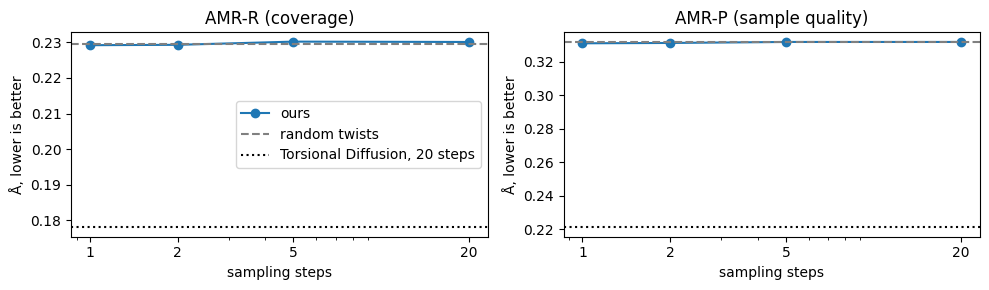

In [13]:
steps = CFG["steps_list"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, col, name in zip(axes, ("AMR_R", "AMR_P"), ("AMR-R (coverage)", "AMR-P (sample quality)")):
    ax.plot(steps, [results[s][col] for s in steps], "o-", label="ours")
    ax.axhline(results[0][col], ls="--", c="gray", label="random twists")
    ax.axhline(table.loc["paper: Torsional Diffusion, 20 steps", col], ls=":", c="k", label="Torsional Diffusion, 20 steps")
    ax.set_xscale("log"); ax.set_xticks(steps, steps); ax.set_xlabel("sampling steps")
    ax.set_ylabel("Å, lower is better"); ax.set_title(name)
axes[0].legend(); plt.tight_layout(); plt.show()

## 7. Reading the result, and what comes next

**In smoke mode, what "working" looks like:** every cell runs, the path check lands back within ~1e-7 Å, and the memorisation check says PASS. The training loss will stay near "predict 0", and generation will be close to "random twists": on this task the network needs tens of thousands of steps before the loss moves, far more than a CPU smoke run gives it. (Measured on this machine: the same network memorises 16 fixed examples in ~200 steps, but makes no progress on the real task in 6000 steps; Torsional Diffusion's own diffusion training also shows no progress in its first ~900 steps.)

**In full mode, on the 5080:**
0. **First, does it learn at all?** Within the first few epochs, the late-time validation numbers should fall well below "predict 0" toward their best-possible values. If after ~10 epochs on the full data nothing has moved, stop: the network may need the twist angles as explicit inputs (as the toy network in the walkthrough had), which would be a change to the model.
1. **Pass condition for step 4:** the 20-step model should come close to Torsional Diffusion's 20-step numbers (AMR-R ≈ 0.178 Å). If it does, flow matching on twist angles works as well as their diffusion. If it's far off, find out why before going further.
2. **The step-count curve is the project's question.** How much worse are 1 and 2 steps than 20? That gap is what step 6's few-step methods (Reflow, consistency, distillation) must close, starting from this trained model (`best_model.pt`).
3. **Losses (step 5):** rerun with `loss="endpoint_cos"`, and compare the curves.

**Before the full run,** do step 2: reproduce Torsional Diffusion's own numbers on this machine. That proves the data and scoring are right, so any gap seen here comes from the model, not the setup.